<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2021%3A%20Factor%20Analysis%20and%20Latent%20Factor%20Interpretation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FactorAnalysis (k=2) Log-Likelihood: -10.6745
FactorAnalysis (k=3) Log-Likelihood: -9.7186
FactorAnalysis (k=4) Log-Likelihood: -9.6969


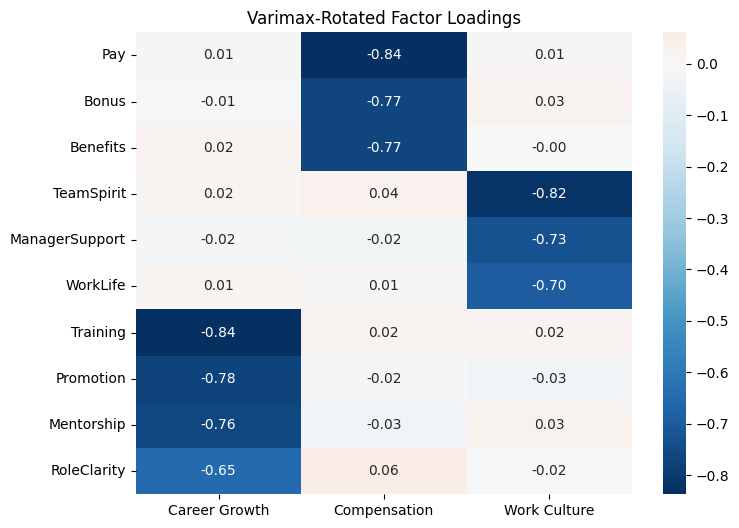


PCA Explained Variance Ratios: [0.32  0.264 0.234]
Factor Analysis models unique item noise separately, giving cleaner latent groupings than PCA.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA

np.random.seed(42)

N = 300
f_comp = np.random.randn(N)
f_cult = np.random.randn(N)
f_grow = np.random.randn(N)

questions = ['Pay', 'Bonus', 'Benefits', 'TeamSpirit', 'ManagerSupport', 'WorkLife', 'Training', 'Promotion', 'Mentorship', 'RoleClarity']
raw = np.column_stack([
    0.85*f_comp + 0.3*np.random.randn(N),
    0.80*f_comp + 0.3*np.random.randn(N),
    0.75*f_comp + 0.4*np.random.randn(N),
    0.85*f_cult + 0.3*np.random.randn(N),
    0.80*f_cult + 0.3*np.random.randn(N),
    0.70*f_cult + 0.4*np.random.randn(N),
    0.85*f_grow + 0.3*np.random.randn(N),
    0.80*f_grow + 0.3*np.random.randn(N),
    0.75*f_grow + 0.4*np.random.randn(N),
    0.65*f_grow + 0.5*np.random.randn(N),
])
df = pd.DataFrame(np.clip(np.round(raw + 3), 1, 5), columns=questions)

for k in [2, 3, 4]:
    fa = FactorAnalysis(n_components=k, random_state=42).fit(df)
    print(f"FactorAnalysis (k={k}) Log-Likelihood: {fa.score(df):.4f}")

fa_varimax = FactorAnalysis(n_components=3, rotation='varimax', random_state=42).fit(df)
loadings = pd.DataFrame(fa_varimax.components_.T, index=questions,
                        columns=['Career Growth', 'Compensation', 'Work Culture'])

plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Varimax-Rotated Factor Loadings")
plt.show()

pca = PCA(n_components=3).fit(df)
print("\nPCA Explained Variance Ratios:", np.round(pca.explained_variance_ratio_, 3))
print("Factor Analysis models unique item noise separately, giving cleaner latent groupings than PCA.")